# 03 · Model Development & Evaluation

1. Compare 3 algorithms × 3 imbalance strategies (+ a baseline) on the **validation** set.
2. Calibrate the best model's probabilities.
3. Choose a clinically motivated decision threshold on validation.
4. Evaluate **once** on the held-out test set.
5. Stratify patients into Low / Moderate / High risk groups.
6. Ablation: how well can we do **without laboratory values**?

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(PROJECT_ROOT))

import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.max_columns", 30)

from src.config import FIGURES_DIR, MODELS_DIR, REPORTS_DIR, TARGET
from src.evaluation import save_fig

In [2]:
import json
import joblib

from src.data_preparation import prepare_dataset, split_data, MODEL_FEATURES, LAB_FEATURES
from src.modeling import compare_models, build_pipeline, calibrate, select_threshold
from src.evaluation import (
    compute_metrics, risk_group_table, plot_roc_pr, plot_calibration,
    plot_confusion, plot_threshold_tradeoff, plot_risk_stratification,
)

df = prepare_dataset()
X_train, X_val, X_test, y_train, y_val, y_test = split_data(df)
print(f"train={len(X_train):,}  val={len(X_val):,}  test={len(X_test):,}")

train=67,288  val=14,420  test=14,420


## 1. Model comparison (validation set)

| Model | Why it is included |
|---|---|
| Logistic Regression | Interpretable baseline; coefficients map to odds ratios |
| Random Forest | Captures non-linearities and interactions (best model in the original capstone) |
| Gradient Boosting (`HistGradientBoostingClassifier`) | Typically the strongest learner on tabular data |

Models are **ranked by PR-AUC** (average precision), which focuses on how well the minority class is ranked and is more informative than ROC-AUC under imbalance. Threshold-based metrics below use the default 0.5 cut-off.

In [3]:
results, fitted = compare_models(X_train, y_train, X_val, y_val)
cols = ["model", "strategy", "roc_auc", "pr_auc", "brier", "sensitivity", "specificity", "precision", "f1"]
results[cols]

,model,strategy,roc_auc,pr_auc,brier,sensitivity,specificity,precision,f1
0,Gradient Boosting,class-weighted,0.9805,0.8926,0.0543,0.9198,0.9119,0.5026,0.6500
1,Gradient Boosting,unweighted,0.9801,0.8910,0.0234,0.6730,0.9988,0.9817,0.7985
2,Gradient Boosting,SMOTE,0.9777,0.8822,0.0254,0.7138,0.9919,0.8946,0.7941
3,Random Forest,class-weighted,0.9768,0.8798,0.0354,0.8050,0.9656,0.6938,0.7453
4,Random Forest,unweighted,0.9755,0.8790,0.0242,0.6730,0.9989,0.9828,0.7989
5,Random Forest,SMOTE,0.9749,0.8722,0.0302,0.7484,0.9817,0.7987,0.7727
6,Logistic Regression,unweighted,0.9666,0.8350,0.0312,0.6313,0.9915,0.8776,0.7343
7,Logistic Regression,SMOTE,0.9671,0.8320,0.0752,0.8962,0.8899,0.4405,0.5907
8,Logistic Regression,class-weighted,0.9672,0.8313,0.0755,0.9002,0.8893,0.4402,0.5913
9,Baseline (prior),-,0.5000,0.0882,0.0804,0.0000,1.0000,0.0000,0.0000


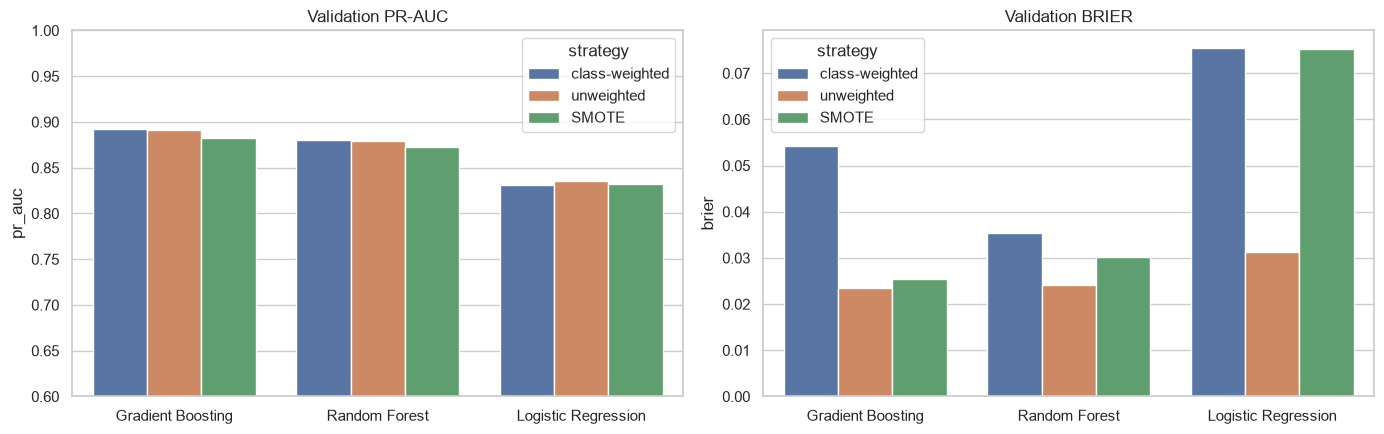

In [4]:
plot_df = results[results.model != "Baseline (prior)"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, metric in zip(axes, ["pr_auc", "brier"]):
    sns.barplot(data=plot_df, x="model", y=metric, hue="strategy", ax=ax)
    ax.set(title=f"Validation {metric.upper().replace('_', '-')}", xlabel="")
    if metric == "pr_auc":
        ax.set_ylim(0.6, 1)
fig.tight_layout()
save_fig(fig, FIGURES_DIR / "validation_model_comparison.png");

**Observations**

* All models are far better than the prevalence baseline (PR-AUC ≈ 0.09).
* **Gradient boosting** gives the best ranking of diabetic patients, with Random Forest close behind; logistic regression lags because the label depends on lab thresholds in a non-linear way.
* **Class weighting and SMOTE barely change ranking (ROC/PR-AUC)** but shift predicted probabilities upwards — they raise sensitivity at 0.5 at the cost of precision and *calibration* (higher Brier score). The same trade-off can be achieved more transparently by **moving the threshold** on a well-calibrated model, which is the approach taken below.

## 2. Calibrated final model

In [5]:
best = results.iloc[0]
best_name, best_strategy = best["model"], best["strategy"]
print(f"Best by validation PR-AUC: {best_name} ({best_strategy})")

# Isotonic calibration with 5-fold CV on the training set
final_model = calibrate(build_pipeline(best_name, best_strategy), X_train, y_train)
uncalibrated = fitted[(best_name, best_strategy)]

p_val_raw = uncalibrated.predict_proba(X_val)[:, 1]
p_val = final_model.predict_proba(X_val)[:, 1]

pd.DataFrame({
    "uncalibrated": compute_metrics(y_val, p_val_raw),
    "calibrated": compute_metrics(y_val, p_val),
}).loc[["roc_auc", "pr_auc", "brier"]]

Best by validation PR-AUC: Gradient Boosting (class-weighted)


,uncalibrated,calibrated
roc_auc,0.9805,0.9802
pr_auc,0.8926,0.8915
brier,0.0543,0.0233


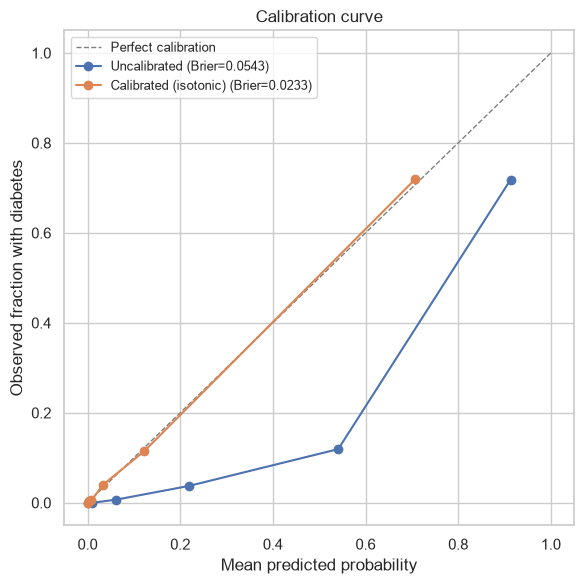

In [6]:
fig = plot_calibration({"Uncalibrated": p_val_raw, "Calibrated (isotonic)": p_val}, y_val)
save_fig(fig, FIGURES_DIR / "validation_calibration_curves.png");

## 3. Choosing the decision threshold

For a **screening** use case, missing a diabetic patient (false negative) is usually costlier than an extra confirmatory test (false positive). The operating threshold is therefore the **highest threshold that keeps validation sensitivity ≥ 90%**. The F1-optimal threshold is reported for comparison.

In [7]:
thr_screen = select_threshold(y_val, p_val, strategy="recall", min_recall=0.90)
thr_f1 = select_threshold(y_val, p_val, strategy="f1")

pd.DataFrame({
    "default (0.50)": compute_metrics(y_val, p_val, 0.5),
    f"F1-optimal ({thr_f1:.2f})": compute_metrics(y_val, p_val, thr_f1),
    f"Screening ({thr_screen:.2f})": compute_metrics(y_val, p_val, thr_screen),
}).loc[["threshold", "sensitivity", "specificity", "precision", "f1", "balanced_accuracy", "tp", "fp", "fn"]]

,default (0.50),F1-optimal (0.33),Screening (0.13)
threshold,0.5000,0.3293,0.1278
sensitivity,0.6698,0.7319,0.9002
specificity,0.9995,0.9913,0.9327
precision,0.9930,0.8909,0.5640
f1,0.8000,0.8036,0.6935
balanced_accuracy,0.8347,0.8616,0.9164
tp,852.0000,931.0000,1145.0000
fp,6.0000,114.0000,885.0000
fn,420.0000,341.0000,127.0000


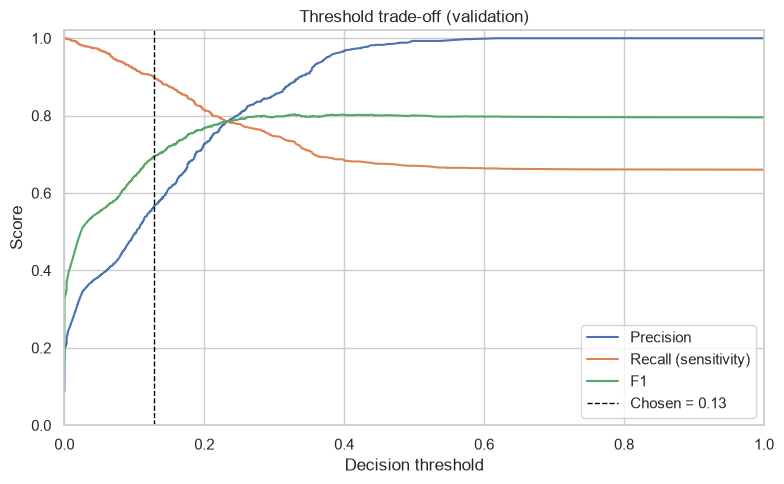

In [8]:
fig = plot_threshold_tradeoff(y_val, p_val, chosen=thr_screen)
save_fig(fig, FIGURES_DIR / "validation_threshold_tradeoff.png");

## 4. Final evaluation on the held-out test set

The test set is used **once**, with the model, calibration and threshold all fixed in advance.

In [9]:
p_test = final_model.predict_proba(X_test)[:, 1]
test_metrics = compute_metrics(y_test, p_test, thr_screen)
pd.Series(test_metrics).to_frame("test")

,test
roc_auc,0.9771
pr_auc,0.8799
brier,0.0235
threshold,0.1278
sensitivity,0.8774
specificity,0.9274
precision,0.5389
f1,0.6677
balanced_accuracy,0.9024
tp,1116.0000


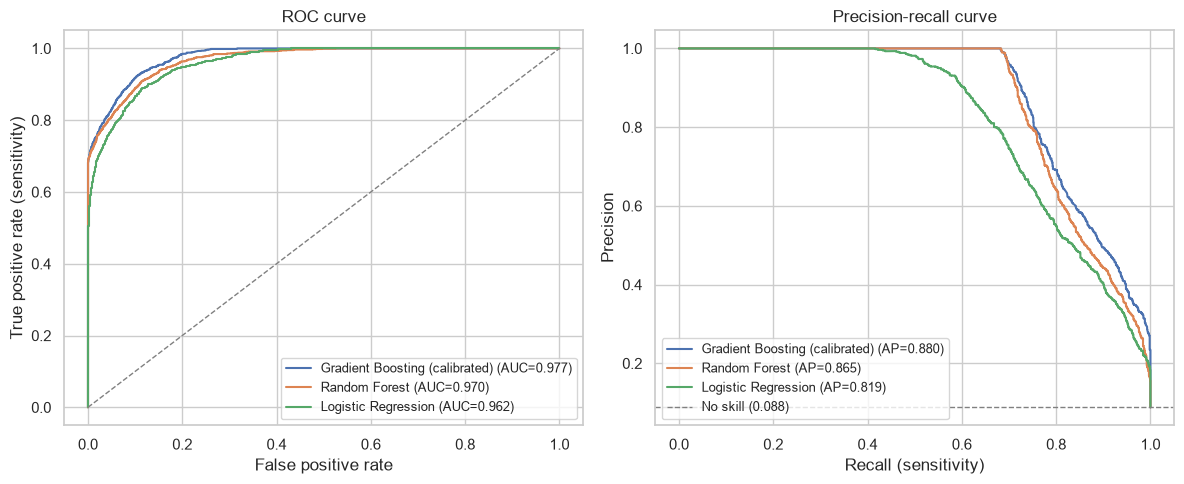

In [10]:
lr = fitted[("Logistic Regression", "unweighted")]
rf = fitted[("Random Forest", "unweighted")]
fig = plot_roc_pr({
    f"{best_name} (calibrated)": p_test,
    "Random Forest": rf.predict_proba(X_test)[:, 1],
    "Logistic Regression": lr.predict_proba(X_test)[:, 1],
}, y_test)
save_fig(fig, FIGURES_DIR / "test_roc_pr_curves.png");

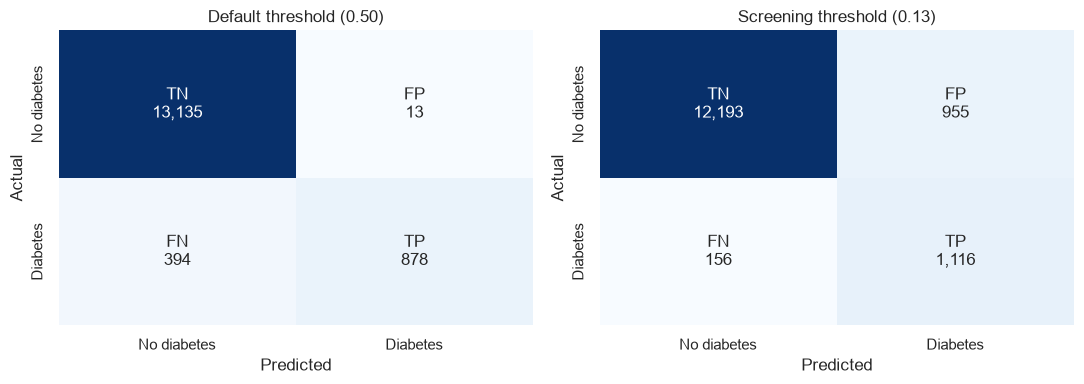

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
plot_confusion(y_test, p_test, 0.5, "Default threshold (0.50)", ax=axes[0])
plot_confusion(y_test, p_test, thr_screen, f"Screening threshold ({thr_screen:.2f})", ax=axes[1])
save_fig(fig, FIGURES_DIR / "test_confusion_matrices.png");

At the screening threshold the model catches roughly 9 in 10 diabetic patients. The price is more false positives — acceptable for a *first-line* screen where a positive leads to a cheap confirmatory test, not a diagnosis.

## 5. Risk stratification

Calibrated probabilities can be grouped into actionable tiers:

| Risk group | Predicted probability | Suggested action |
|---|---|---|
| Low | p < 2% | Routine care |
| Moderate | 2% ≤ p < 20% | Lifestyle advice, periodic re-testing |
| High | p ≥ 20% | Confirmatory diagnostic testing |

In [12]:
CUTOFFS = (0.02, 0.20)
risk_table = risk_group_table(y_test, p_test, CUTOFFS)
risk_table

,individuals,observed_diabetes,mean_predicted_risk,share_of_all_cases
group,,,,
Low,10376,0.0014,0.0019,0.0118
Moderate,2603,0.0953,0.0893,0.1950
High,1441,0.7002,0.7214,0.7932


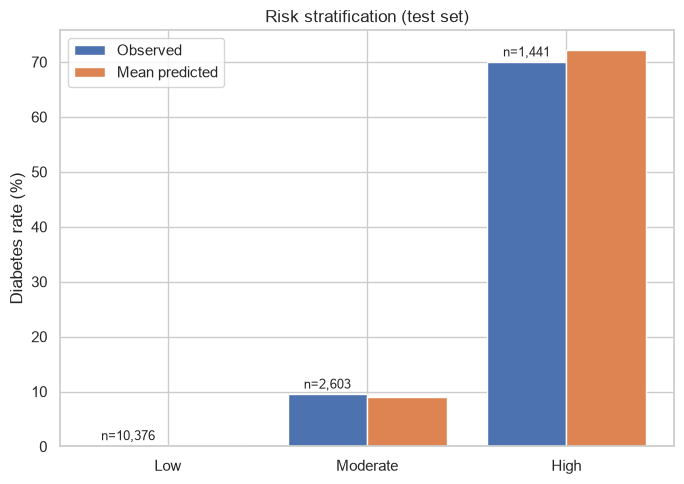

In [13]:
fig = plot_risk_stratification(risk_table)
save_fig(fig, FIGURES_DIR / "test_risk_stratification.png");

Observed diabetes rates rise sharply across tiers and closely match the mean predicted risk in each — evidence that the calibrated probabilities are trustworthy at group level.

## 6. Ablation: a lab-free screening model

Because HbA1c and glucose partly define the label (notebook 01), we retrain the best configuration **without** `HbA1c_level`, `blood_glucose_level`, `glucose_hba1c` and `prediabetes_flag`. This answers a more realistic question: *who should be sent for a blood test in the first place?*

In [14]:
from src.data_preparation import CONTINUOUS_FEATURES, BINARY_FEATURES, CATEGORICAL_FEATURES
from src.preprocessing import build_preprocessor

nolab_features = [f for f in MODEL_FEATURES if f not in LAB_FEATURES]
nolab_pre = build_preprocessor(
    continuous_features=[f for f in CONTINUOUS_FEATURES if f in nolab_features],
    binary_features=[f for f in BINARY_FEATURES if f in nolab_features],
    categorical_features=CATEGORICAL_FEATURES,
)
nolab_model = calibrate(build_pipeline(best_name, best_strategy, preprocessor=nolab_pre),
                        X_train[nolab_features], y_train)

p_val_nolab = nolab_model.predict_proba(X_val[nolab_features])[:, 1]
thr_nolab = select_threshold(y_val, p_val_nolab, strategy="recall", min_recall=0.90)
p_test_nolab = nolab_model.predict_proba(X_test[nolab_features])[:, 1]

ablation = pd.DataFrame({
    "with lab values": test_metrics,
    "without lab values": compute_metrics(y_test, p_test_nolab, thr_nolab),
}).loc[["roc_auc", "pr_auc", "brier", "threshold", "sensitivity", "specificity", "precision"]]
print("Features used without labs:", nolab_features)
ablation

Features used without labs: ['age', 'bmi', 'age_bmi', 'hypertension', 'heart_disease', 'gender', 'smoking_history']


,with lab values,without lab values
roc_auc,0.9771,0.8270
pr_auc,0.8799,0.3077
brier,0.0235,0.0694
threshold,0.1278,0.0527
sensitivity,0.8774,0.8931
specificity,0.9274,0.5870
precision,0.5389,0.1730


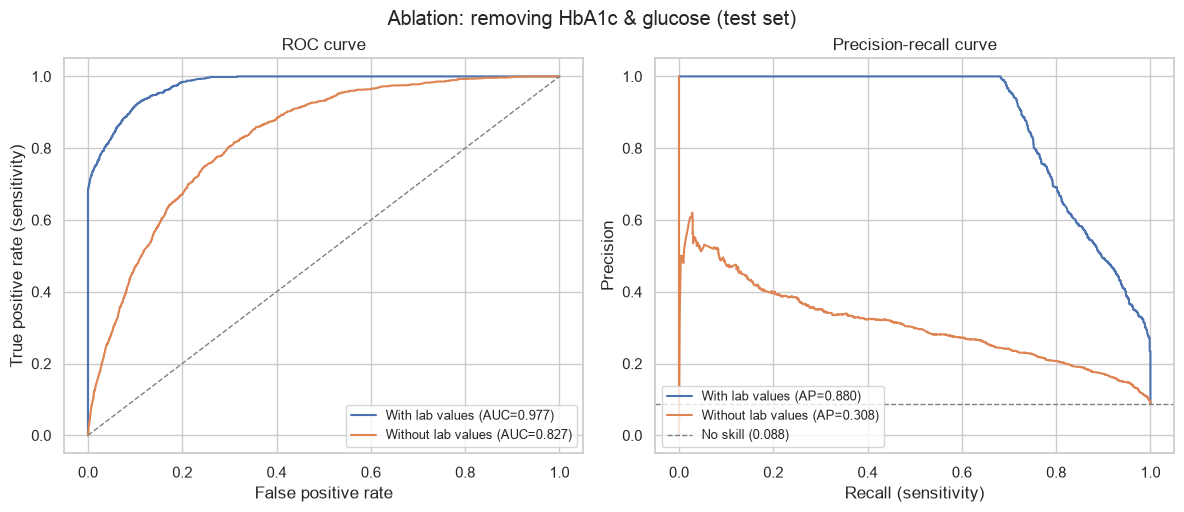

In [15]:
fig = plot_roc_pr({"With lab values": p_test, "Without lab values": p_test_nolab}, y_test)
fig.suptitle("Ablation: removing HbA1c & glucose (test set)", y=1.02)
save_fig(fig, FIGURES_DIR / "test_ablation_no_lab.png");

Without lab values, discrimination drops substantially but remains well above chance, driven by age, BMI, hypertension and heart disease. To reach 90% sensitivity the lab-free model must flag many more patients — consistent with its role as a cheap **pre-screen** that decides who gets a blood test, after which the full model applies.

## 7. Save artefacts

In [16]:
MODELS_DIR.mkdir(exist_ok=True)
joblib.dump(final_model, MODELS_DIR / "final_model.joblib")
joblib.dump(uncalibrated, MODELS_DIR / "best_pipeline_uncalibrated.joblib")
joblib.dump(fitted[("Logistic Regression", "unweighted")], MODELS_DIR / "logistic_regression.joblib")

summary = {
    "best_model": f"{best_name} ({best_strategy}) + isotonic calibration",
    "screening_threshold": round(thr_screen, 4),
    "risk_cutoffs": list(CUTOFFS),
    "test_metrics": {k: (round(float(v), 4) if isinstance(v, float) else v) for k, v in test_metrics.items()},
    "test_metrics_no_lab": {k: round(float(v), 4) for k, v in ablation["without lab values"].items()},
    "risk_groups_test": risk_table.round(4).reset_index().astype({"group": str}).to_dict(orient="records"),
}
(REPORTS_DIR / "metrics.json").write_text(json.dumps(summary, indent=2))
results[cols].round(4).to_csv(REPORTS_DIR / "validation_model_comparison.csv", index=False)
print(json.dumps(summary, indent=2))

{
  "best_model": "Gradient Boosting (class-weighted) + isotonic calibration",
  "screening_threshold": 0.1278,
  "risk_cutoffs": [
    0.02,
    0.2
  ],
  "test_metrics": {
    "roc_auc": 0.9771,
    "pr_auc": 0.8799,
    "brier": 0.0235,
    "threshold": 0.1278,
    "sensitivity": 0.8774,
    "specificity": 0.9274,
    "precision": 0.5389,
    "f1": 0.6677,
    "balanced_accuracy": 0.9024,
    "tp": 1116,
    "fp": 955,
    "fn": 156,
    "tn": 12193
  },
  "test_metrics_no_lab": {
    "roc_auc": 0.827,
    "pr_auc": 0.3077,
    "brier": 0.0694,
    "threshold": 0.0527,
    "sensitivity": 0.8931,
    "specificity": 0.587,
    "precision": 0.173
  },
  "risk_groups_test": [
    {
      "group": "Low",
      "individuals": 10376,
      "observed_diabetes": 0.0014,
      "mean_predicted_risk": 0.0019,
      "share_of_all_cases": 0.0118
    },
    {
      "group": "Moderate",
      "individuals": 2603,
      "observed_diabetes": 0.0953,
      "mean_predicted_risk": 0.0893,
      "share_